# Metaheuristics for Multi Resource Workload Allocation
**CSCU9YE Artificial Intelligence · Option 1**

This study selects AI models under simultaneous hardware limits. Part 1 develops a discrete hill-climbing baseline on the 28-model instance. Part 2 implements a binary genetic algorithm on the 90-model instance. Part 3 compares that GA with restarted hill climbing under equal evaluation budgets. All search and statistical randomisation logic is implemented below using NumPy and the Python standard library; Matplotlib produces the figures.

The notebook follows the course progression: representation and evaluation, neighbourhood moves, population search, then controlled comparison. The integrated code, outputs and analysis form the Option 1 submission.

**Results.** Across 30 n28 runs at 3000 evaluations, the mixed-neighbour HC achieved median utility **115,492.5**. On n90, at 10000 evaluations per run and 30 runs per method, GA and restart-HC achieved medians **11,071.5** and **11,049.0**. The two-sided permutation test gave **p = 0.5001**, with **A = 0.551**. The predicted GA advantage was not supported. Restart-HC is the preferred method for this fixed setup: its observed utility distribution is close to GA's and its median search time is lower. All 90 archived deployments satisfy every resource constraint.

## 1 Problem and data

For model $j$, $x_j=1$ means deploy and $x_j=0$ means omit. Utility is additive, and a deployment must satisfy every resource limit:

$$\max_{x\in\{0,1\}^n} f(x)=\sum_{j=1}^n p_jx_j,
\qquad \sum_{j=1}^n r_{ij}x_j\le b_i\quad(i=1,\ldots,m).$$

This is a single-objective, multi-constraint 0–1 selection problem. Utilities and resource demands are supplied; no machine-learning model is trained. The formulation assumes independent, additive contributions and fixed capacities. Interactions between deployed models are outside this formulation.

| Instance | Models | Resources | Role |
|---|---:|---:|---|
| `multi_resource_n28_m2.txt` | 28 | 2 | Baseline design and evaluation |
| `multi_resource_n90_m5.txt` | 90 | 5 | GA and controlled comparison |

There are $2^{28}$ and $2^{90}$ binary candidates respectively. Local and evolutionary search sample this space rather than enumerate it. Week 2's value/weight knapsack becomes a demand matrix: rows are resources, columns are models. All limits must pass; spare capacity in one row cannot compensate for excess in another. The official loader reads whitespace-separated blocks, so wrapped text lines do not change the data.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import platform
import time
import math
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from workload_data_loader import load_workload_instance

# Fixed protocol
RUNS = 30
BASELINE_BUDGET = 3000
STUDY_BUDGET = 10000
RESTARTS = 5
POPULATION = 40
TOURNAMENT = 3
CROSSOVER_RATE = 0.9
SELECT_PROBABILITY = 0.2
MASTER_SEED = 3368829
OUT = Path("results")
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.bbox": "tight"})

# Official instances
instances = {}
for label, n_expected, m_expected in [("n28",28,2), ("n90",90,5)]:
    n, m, p, r, b = load_workload_instance(f"multi_resource_{label}_m{m_expected}.txt")
    assert (n,m) == (n_expected,m_expected)
    assert (p.shape,r.shape,b.shape) == ((n,),(m,n),(m,))
    assert np.all(p > 0) and np.all(r >= 0) and np.all(b > 0)
    instances[label] = (p,r,b)
display(Markdown("| Instance | Models | Resources | Capacities |\n|---|---:|---:|---|\n"+
    "\n".join(f"| {label} | {len(p)} | {len(b)} | {b.astype(int).tolist()} |"
               for label,(p,r,b) in instances.items())))
display(Markdown(f"**Environment:** Python {platform.python_version()}; NumPy {np.__version__}; Matplotlib {matplotlib.__version__}."))

| Instance | Models | Resources | Capacities |
|---|---:|---:|---|
| n28 | 28 | 2 | [500, 500] |
| n90 | 90 | 5 | [2100, 1100, 3300, 3700, 3600] |

**Environment:** Python 3.12.16; NumPy 2.5.5; Matplotlib 3.11.2.

### 1.1 Evaluate a deployment

`p @ x` gives utility; `r @ x` gives one usage total per resource. Raw utility and feasibility remain separate. Both solvers reject infeasible proposals instead of adjusting utility with a penalty coefficient. This makes feasibility explicit and keeps the comparison focused on search strategy. Deb (2000) motivates separating constraint satisfaction from objective quality; the implementation here uses direct rejection, not his full infeasible-solution ranking scheme [4].

**Worked calculation.** In n28, models 1 and 2 have utilities 1898 and 440, and demands $(45,30)$ and $(0,20)$. Selecting both gives utility **2338**, usage **(45,50)**, and satisfies capacities **(500,500)**. An empty deployment is feasible with utility zero.

In [2]:
def evaluate(x, instance):
    p, r, b = instance
    usage = r @ x
    return float(p @ x), usage, bool(np.all(usage <= b))

p, r, b = instances["n28"]
example = np.zeros(len(p), dtype=np.int8)
example[:2] = 1
value, usage, feasible = evaluate(example, instances["n28"])
assert value == 2338 and np.array_equal(usage,[45,50]) and feasible
display(Markdown(f"**Models 1 and 2:** utility **{value:g}**; resource usage **{usage.astype(int).tolist()}**; feasible **{feasible}**."))

**Models 1 and 2:** utility **2338**; resource usage **[45, 50]**; feasible **True**.

### 1.2 Count search effort once

One evaluation computes utility and all resource totals for one complete deployment. The same evaluator counts initial candidates, rejected candidates, duplicates and all restart starts. Previously stored fitness is reused for selection and replacement. Search stops at the exact budget. Post-run checks verify saved deployments separately and never feed improvements back into the search.

The evaluator archives the best feasible deployment after every evaluation. This best-so-far trace cannot decrease. Elapsed search time includes candidate generation, scoring, acceptance and population operations; plotting, statistical analysis and post-run checks are excluded. The feasible-proposal fraction measures how often scored candidates satisfy all limits, not the fraction of the entire search space that is feasible.

In [3]:
class Evaluator:
    def __init__(self, instance, budget):
        self.instance, self.budget = instance, budget
        self.count = self.feasible_count = 0
        self.best = -np.inf
        self.best_x = None
        self.trace = np.empty(budget)

    def score(self, x):
        if self.count == self.budget:
            raise RuntimeError("Evaluation budget exhausted")
        value, _, feasible = evaluate(x, self.instance)
        self.feasible_count += int(feasible)
        if feasible and value > self.best:
            self.best, self.best_x = value, x.copy()
        self.trace[self.count] = self.best
        self.count += 1
        return value, feasible

def run(solver, instance, budget, seed):
    evaluator = Evaluator(instance, budget)
    rng = np.random.default_rng(seed)
    started = time.perf_counter()
    solver(evaluator, rng)
    seconds = time.perf_counter() - started

    # Independent output checks
    x = evaluator.best_x
    value, usage, feasible = evaluate(x, instance)
    assert evaluator.count == budget and feasible and value == evaluator.best
    assert np.all((x == 0) | (x == 1)) and np.all(np.diff(evaluator.trace) >= 0)
    return dict(seed=int(seed), utility=value, seconds=seconds, evaluations=evaluator.count,
                feasible_fraction=evaluator.feasible_count/evaluator.count,
                deployment=x, usage=usage, trace=evaluator.trace)

## 2 Part 1 Discrete hill climbing on n28

The baseline adapts `hc_swap` from `classroom_search.py`: with probability 0.5, flip one random bit; otherwise, swap one selected and one unselected model. When a swap is unavailable, use a bit flip. The proposal is accepted exactly when it is feasible and its utility is at least the current utility. An all-zero start is evaluated, then one sparse random start is tried; an infeasible start falls back to the known empty deployment.

**Design rationale.** A one-bit neighbourhood has $n$ members. With positive utilities, removing a selected model always reduces utility, so improving-only bit flips can become an add-only trap. A swap evaluates removal and addition together. It preserves the number of selected models, while bit flips allow that number to change. This combines two complementary moves without introducing crossover into a single-solution algorithm. The choice of neighbourhood defines local optimality [1].

The 50:50 mixture is a fixed balance between changing cardinality and replacing models. Strictly better moves improve utility; equal moves permit movement across plateaus. A finite evaluation budget bounds sideways movement. Random sampling of neighbours follows the Week 3 lab; it is not Week 7's exhaustive best-improvement scan.

**Worked move.** From `11001`, flipping position 3 gives `11101`. Swapping selected position 2 with unselected position 4 gives `10011`. Every proposed move still needs the resource check. A flat trace alone does not certify local optimality.

In [4]:
def neighbour(x, rng):
    selected = np.flatnonzero(x)
    omitted = np.flatnonzero(x == 0)
    y = x.copy()

    # Add/drop or exchange
    if rng.random() < 0.5 or len(selected) == 0 or len(omitted) == 0:
        j = rng.integers(len(x))
        y[j] = 1 - y[j]
    else:
        y[rng.choice(selected)] = 0
        y[rng.choice(omitted)] = 1
    return y

def hill_climb(evaluator, rng, restarts=1):
    n = len(evaluator.instance[0])
    block_sizes = np.full(restarts, evaluator.budget // restarts)
    block_sizes[:evaluator.budget % restarts] += 1

    for block_size in block_sizes:
        # Fresh start, shared global archive
        current = np.zeros(n, dtype=np.int8)
        current_value, _ = evaluator.score(current)
        candidate = (rng.random(n) < SELECT_PROBABILITY).astype(np.int8)
        value, feasible = evaluator.score(candidate)
        if feasible:
            current, current_value = candidate, value

        # Feasible non-decreasing moves
        for _ in range(int(block_size)-2):
            candidate = neighbour(current, rng)
            value, feasible = evaluator.score(candidate)
            if feasible and value >= current_value:
                current, current_value = candidate, value

def hc(evaluator, rng):
    hill_climb(evaluator, rng, restarts=1)

def restart_hc(evaluator, rng):
    hill_climb(evaluator, rng, restarts=RESTARTS)

### 2.1 Repeated baseline runs

Thirty independently seeded n28 runs receive 3000 evaluations each. Reported metrics describe the final best feasible utility, its variability, runtime and the feasible-proposal fraction. The curve shows the median incumbent and interquartile range at each cumulative evaluation, using all runs rather than selecting a favourable trace.

| Method | Mean | SD | Median | Q1–Q3 | Best | Median seconds | Feasible proposals |
|---|---:|---:|---:|---:|---:|---:|---:|
| HC on n28 | 114602.0 | 5852.6 | 115492.5 | 110139.5–118268.5 | 123910 | 0.0883 | 44.0% |

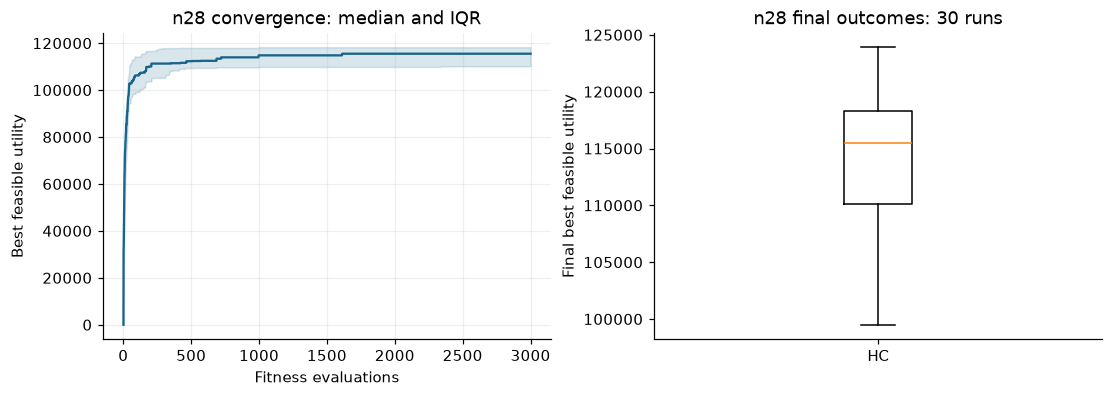

In [5]:
# Independent streams for each study group
seed_groups = np.random.SeedSequence(MASTER_SEED).spawn(4)
def make_seeds(group):
    return [int(child.generate_state(1,dtype=np.uint64)[0]) for child in group.spawn(RUNS)]

baseline_seeds = make_seeds(seed_groups[0])
hc_seeds = make_seeds(seed_groups[1])
ga_seeds = make_seeds(seed_groups[2])
order_rng = np.random.default_rng(seed_groups[3])
baseline = [run(hc, instances["n28"], BASELINE_BUDGET, seed) for seed in baseline_seeds]

def describe(runs):
    values = np.array([r["utility"] for r in runs])
    return dict(mean=float(values.mean()), sd=float(values.std(ddof=1)),
                median=float(np.median(values)), q1=float(np.quantile(values,.25)),
                q3=float(np.quantile(values,.75)), best=float(values.max()),
                seconds=float(np.median([r["seconds"] for r in runs])),
                feasible_fraction=float(np.mean([r["feasible_fraction"] for r in runs])))

def result_table(groups):
    lines = ["| Method | Mean | SD | Median | Q1–Q3 | Best | Median seconds | Feasible proposals |",
             "|---|---:|---:|---:|---:|---:|---:|---:|"]
    for name, runs in groups.items():
        s = describe(runs)
        lines.append(f"| {name} | {s['mean']:.1f} | {s['sd']:.1f} | {s['median']:.1f} | "
                     f"{s['q1']:.1f}–{s['q3']:.1f} | {s['best']:.0f} | {s['seconds']:.4f} | "
                     f"{100*s['feasible_fraction']:.1f}% |")
    display(Markdown("\n".join(lines)))

def convergence(ax, runs, label, color):
    traces = np.stack([r["trace"] for r in runs])
    q1, median, q3 = np.quantile(traces,[.25,.5,.75],axis=0)
    evaluations = np.arange(1,traces.shape[1]+1)
    ax.plot(evaluations,median,label=label,color=color)
    ax.fill_between(evaluations,q1,q3,color=color,alpha=.16)
    ax.set(xlabel="Fitness evaluations",ylabel="Best feasible utility")
    ax.grid(alpha=.2)

result_table({"HC on n28":baseline})
fig, axes = plt.subplots(1,2,figsize=(10,3.5),layout="constrained")
convergence(axes[0],baseline,"HC","#17658a")
axes[0].set_title("n28 convergence: median and IQR")
axes[1].boxplot([r["utility"] for r in baseline])
axes[1].set(xticks=[1],xticklabels=["HC"],ylabel="Final best feasible utility",
            title="n28 final outcomes: 30 runs")
fig.savefig(OUT/"part1_baseline.png",dpi=180)
plt.show()

**Baseline findings.** HC reached mean utility 114,602.0, median 115,492.5 and best-found utility 123,910 on n28. The interquartile range was 110,139.5–118,268.5, showing dependence on random starts and proposals. Only 44.0% of scored proposals were feasible, although all 30 returned deployments were feasible. Swap moves provide direct replacements that single-bit improvement can miss; they also generate infeasible candidates when the entering model exceeds a resource limit. The plateau in the aggregated curve records reduced progress under the budget, not a certificate of global optimality.

**Baseline findings.** HC reached mean utility 114,602.0, median 115,492.5 and best-found utility 123,910 on n28. The interquartile range was 110,139.5–118,268.5, showing dependence on random starts and proposals. Only 44.0% of scored proposals were feasible, although all 30 returned deployments were feasible. Swap moves provide direct replacements that single-bit improvement can miss; they also generate infeasible candidates when the entering model exceeds a resource limit. The plateau in the aggregated curve records reduced progress under the budget, not a certificate of global optimality.

## 3 Part 2 Binary genetic algorithm on n90

The GA maintains 40 binary deployments and uses steady-state replacement: one final child is evaluated per update. Row 0 of the initial population is empty; the remaining bits are independently selected with probability 0.2. This supplies a feasible reference and varied sparse candidates without a construction heuristic. Infeasible initial members have fitness $-\infty$ and are replaced before better feasible members.

| Stage | Choice and reason |
|---|---|
| Parent selection | Three-way tournament, without replacement within each tournament; rank-based preference avoids scaling utilities into roulette probabilities. |
| Crossover | Uniform crossover with probability 0.9; each position chooses its source parent with probability 0.5. Model order has no specified linkage, so contiguous segments receive no special status [2]. |
| Mutation | Independent bit flips with probability $1/n$; expected flips per child are one, while zero or multiple flips remain possible. |
| Constraint handling | Score every final child; reject infeasible children. No repair search or hidden evaluations. |
| Replacement | Replace the worst population member only with a feasible, strictly better child; the population's best feasible value is retained. |

Uniform crossover can combine decisions from different useful deployments; theoretical work demonstrates benefits on particular building-block functions [3]. Here the shared resource constraints couple decisions, so this is a mechanism to test, not an optimality result for workload allocation. Mutation can introduce decisions lost through selection. Feasible rejection makes accounting transparent but discards information from near-feasible children. Larger populations increase initial diversity and consume more of the budget before offspring search; larger tournaments increase selection pressure and can accelerate loss of diversity.

**Hand calculations.** For fitness ranks $1,2,3,4$ from best to worst, a three-way tournament sampled without replacement selects rank 1 with probability $\binom{3}{2}/\binom{4}{3}=3/4$, and rank 2 with probability $1/4$. For parents `1100` and `0011`, choosing parent 1 at positions 1 and 4 gives child `1010`. On n90, mutation has $E[K]=90(1/90)=1$ and $P(K=0)=(89/90)^{90}\approx0.366$. This differs from a 0.2 probability of one swap per child in the routing lecture.

**Hint.** Selection uses stored fitness. Crossover and mutation finish before the child is scored, so their intermediate arrays do not receive extra uncounted objective evaluations.

**Parameter predictions.** These predictions follow the mechanisms; the experiment keeps the listed settings fixed.

| Change | Predicted consequence |
|---|---|
| HC uses only one-bit moves | Profitable exchanges requiring removal followed by addition become inaccessible to improving-only moves. |
| More restarts at the same total budget | Broader starting-point coverage, less time to improve each trajectory. |
| Larger GA population | More initial variety, fewer offspring evaluations within the fixed budget. |
| Larger tournament | Stronger selection pressure, faster loss of less-fit genetic material. |
| Crossover rate becomes zero | Parent cloning plus mutation; recombination is removed. |
| Mutation becomes zero | No new bit values are introduced once lost from the population. |
| Mutation becomes large | Larger disruptions; more useful combinations may be destroyed and feasibility may worsen. |

The choices retain distinct mechanisms: restart-HC preserves one working deployment within each block; GA retains a population throughout the run.

In [6]:
def tournament(population, fitness, rng):
    contenders = rng.choice(len(population),size=TOURNAMENT,replace=False)
    return population[contenders[np.argmax(fitness[contenders])]]

def genetic_algorithm(evaluator, rng):
    n = len(evaluator.instance[0])
    population = (rng.random((POPULATION,n)) < SELECT_PROBABILITY).astype(np.int8)
    population[0] = 0
    fitness = np.full(POPULATION,-np.inf)

    # Initial population consumes budget
    for i, x in enumerate(population):
        value, feasible = evaluator.score(x)
        if feasible:
            fitness[i] = value

    while evaluator.count < evaluator.budget:
        # Select, mix, mutate
        parent_a = tournament(population,fitness,rng)
        parent_b = tournament(population,fitness,rng)
        if rng.random() < CROSSOVER_RATE:
            child = np.where(rng.random(n)<0.5,parent_a,parent_b).copy()
        else:
            child = parent_a.copy()
        mutation = rng.random(n) < 1/n
        child[mutation] = 1-child[mutation]

        # Score once, retain strong feasible members
        value, feasible = evaluator.score(child)
        worst = np.argmin(fitness)
        if feasible and value > fitness[worst]:
            population[worst] = child
            fitness[worst] = value

## 4 Part 3 Restart HC versus GA on n90

**Research question.** Under 10000 evaluations, does retaining and recombining a population yield better final feasible utility than dividing the same budget among five local-search starts?

**Directional research hypothesis.** The GA will produce higher final feasible utility because selection retains multiple useful deployments and crossover can recombine their decisions. Restart-HC repeatedly discards its current deployment and gives each local trajectory only 2000 evaluations. The competing mechanism is strong local exploitation: swap moves can make direct profitable replacements, while GA offspring may duplicate parents or violate constraints. The comparison tests these two complete search designs, rather than attributing a difference solely to crossover.

| Control | Protocol |
|---|---|
| Instance and objective | Official n90; maximise feasible utility |
| Budget | Exactly 10000 complete scores per run, including all starts and population members |
| Replications | 30 independent runs per method; distinct reproducible seed streams |
| Restart-HC | Same mixed-neighbour HC as Part 1; five equal blocks of 2000 evaluations |
| GA | Exactly the implementation from Part 2; no additional local search |
| Initial bits | Selection probability 0.2 in both methods; empty feasible references |
| Run order | Randomised HC/GA order within each experimental block, sequential execution |
| Primary outcome | Final best feasible utility |
| Secondary outcomes | Convergence, elapsed search time and feasible-proposal fraction |
| Inference | Two-sided permutation-calibrated Mann–Whitney U statistic; significance level 0.05 |

The populations and trajectories are independently randomised. The execution blocks control scheduling only: they are not matched solution pairs. Settings are fixed before this notebook's experiment, using course mechanisms and the existing classroom implementation; no n90 parameter sweep or selection of favourable seeds is performed here. Previous classroom exploration informed the neighbourhood choice, so the experiment is confirmatory for these fixed settings, not an untouched-data validation exercise.

The Week 7 example uses ten runs on a routing problem. This experiment uses the assignment's minimum of thirty runs per method and plots utility upwards because this problem is maximisation. SA and ACO are alternative families; they are not additional requirements for this selected comparison.

In [7]:
# Independent outcomes, balanced scheduling
study = {"Restart-HC":[], "GA":[]}
schedule = []
for i in range(RUNS):
    order = ["Restart-HC","GA"] if order_rng.random()<0.5 else ["GA","Restart-HC"]
    schedule.append(order)
    for name in order:
        solver = restart_hc if name == "Restart-HC" else genetic_algorithm
        seed = hc_seeds[i] if name == "Restart-HC" else ga_seeds[i]
        study[name].append(run(solver,instances["n90"],STUDY_BUDGET,seed))

assert len(set(baseline_seeds+hc_seeds+ga_seeds)) == 3*RUNS
result_table(study)
display(Markdown(f"**Experiment complete:** {RUNS} runs per method, {STUDY_BUDGET:,} evaluations per run."))

| Method | Mean | SD | Median | Q1–Q3 | Best | Median seconds | Feasible proposals |
|---|---:|---:|---:|---:|---:|---:|---:|
| Restart-HC | 11029.9 | 90.3 | 11049.0 | 10965.2–11102.2 | 11153 | 0.3148 | 41.1% |
| GA | 11037.2 | 114.0 | 11071.5 | 10969.0–11129.5 | 11164 | 0.5571 | 67.5% |

**Experiment complete:** 30 runs per method, 10,000 evaluations per run.

### 4.1 Outcome distributions and convergence

Each box contains thirty independent final outcomes. Curves show the median and interquartile range of the archived feasible utility against cumulative evaluations. Initialisation is included on the horizontal axis. Equal evaluation budgets control scored search effort; measured runtime additionally captures the different costs of neighbourhood generation and population operations.

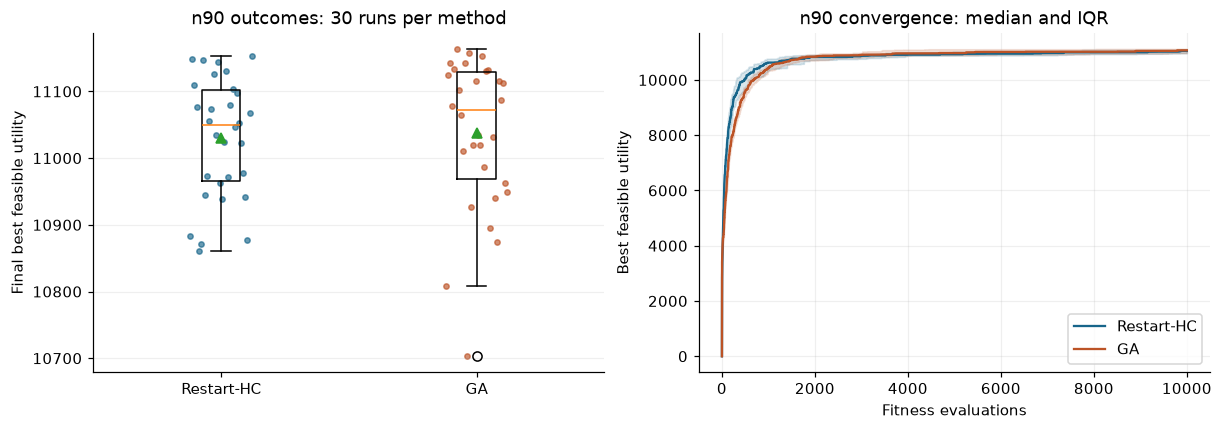

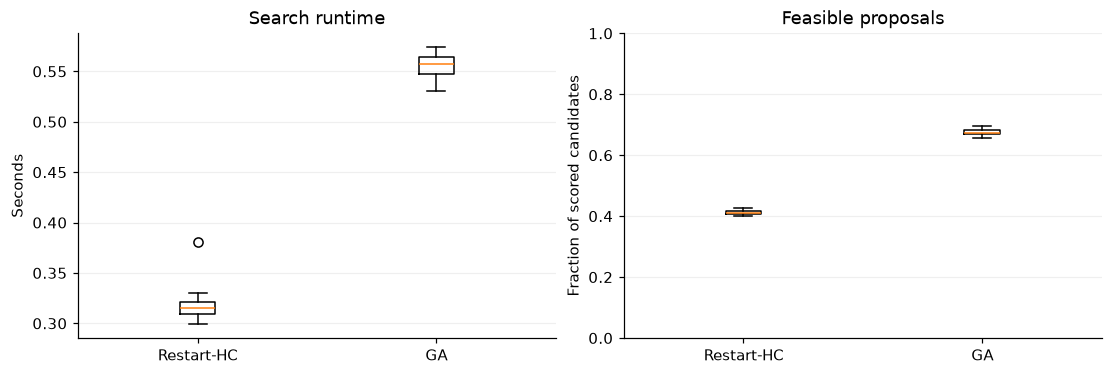

In [8]:
names = list(study)
colors = ["#17658a","#bc5326"]
fig, axes = plt.subplots(1,2,figsize=(11,3.8),layout="constrained")
axes[0].boxplot([[r["utility"] for r in study[name]] for name in names],
                tick_labels=names,showmeans=True)
for j,(name,color) in enumerate(zip(names,colors),1):
    values = [r["utility"] for r in study[name]]
    axes[0].scatter(np.linspace(j-.12,j+.12,RUNS),values,s=12,alpha=.65,color=color)
    convergence(axes[1],study[name],name,color)
axes[0].set(ylabel="Final best feasible utility",title="n90 outcomes: 30 runs per method")
axes[0].grid(axis="y",alpha=.2)
axes[1].set_title("n90 convergence: median and IQR")
axes[1].legend()
fig.savefig(OUT/"part3_quality.png",dpi=180)
plt.show()

fig, axes = plt.subplots(1,2,figsize=(10,3.3),layout="constrained")
for ax,field,ylabel,title in [(axes[0],"seconds","Seconds","Search runtime"),
                             (axes[1],"feasible_fraction","Fraction of scored candidates","Feasible proposals")]:
    ax.boxplot([[r[field] for r in study[name]] for name in names],tick_labels=names)
    ax.set(ylabel=ylabel,title=title)
    ax.grid(axis="y",alpha=.2)
axes[1].set_ylim(0,1)
fig.savefig(OUT/"part3_cost.png",dpi=180)
plt.show()

### 4.2 Non-parametric test and effect size

The statistical null is that the two final-utility distributions are identical. A two-sided test permits evidence in either direction even though the research prediction favours GA. Independent runs are the sampling units; points within a convergence curve are not independent observations.

The Mann–Whitney statistic counts cross-method wins, awarding half a win to ties [5]. The effect size $A=P(GA>HC)+\tfrac12P(GA=HC)$ is estimated over all $30\times30$ outcome pairs. $A>0.5$ favours GA; $2A-1$ is Cliff's delta. To handle discrete utilities and ties directly, the U statistic is calibrated by 19999 random label permutations, retaining sample sizes. The Monte Carlo p-value uses $(b+1)/(B+1)$; its resolution is 0.00005. This tests distributions, not exclusively equality of medians.

A separate 10000-resample bootstrap gives a percentile 95% interval for the difference in medians (GA minus HC). It quantifies run-to-run uncertainty on this fixed instance. The primary utility test is the only significance test; runtime and feasibility are descriptive outcomes.

In [9]:
def compare_utilities(hc_values, ga_values, permutations=19999):
    # Tie-aware pairwise wins
    differences = ga_values[:,None]-hc_values[None,:]
    u_ga = float(np.sum(differences>0)+0.5*np.sum(differences==0))
    total_pairs = len(ga_values)*len(hc_values)
    effect_a = u_ga/total_pairs

    # Average ranks, then permute labels
    pooled = np.concatenate([ga_values,hc_values])
    _, inverse, counts = np.unique(pooled,return_inverse=True,return_counts=True)
    ends = np.cumsum(counts)
    ranks = (ends-counts+(counts+1)/2)[inverse]
    n = len(ga_values)
    centre = total_pairs/2
    observed = abs(u_ga-centre)
    rng = np.random.default_rng(741902)
    extreme = 0
    for _ in range(permutations):
        indices = rng.permutation(len(pooled))[:n]
        u_permuted = ranks[indices].sum()-n*(n+1)/2
        extreme += abs(u_permuted-centre) >= observed-1e-12
    p_value = (extreme+1)/(permutations+1)

    # Resample independent groups
    rng = np.random.default_rng(741903)
    boot_ga = np.median(rng.choice(ga_values,(10000,n)),axis=1)
    boot_hc = np.median(rng.choice(hc_values,(10000,len(hc_values))),axis=1)
    interval = np.quantile(boot_ga-boot_hc,[.025,.975])
    return dict(u_ga=u_ga, effect_a=effect_a, cliffs_delta=2*effect_a-1,
                p_value=p_value, permutations=permutations,
                median_difference=float(np.median(ga_values)-np.median(hc_values)),
                ci_low=float(interval[0]),ci_high=float(interval[1]))

hc_values = np.array([r["utility"] for r in study["Restart-HC"]])
ga_values = np.array([r["utility"] for r in study["GA"]])
statistics = compare_utilities(hc_values,ga_values)
display(Markdown(
    f"**GA minus HC median difference:** {statistics['median_difference']:.1f}; "
    f"bootstrap 95% interval [{statistics['ci_low']:.1f}, {statistics['ci_high']:.1f}].  \n"
    f"**U (GA):** {statistics['u_ga']:.1f}; **two-sided permutation p:** {statistics['p_value']:.5f}; "
    f"**A:** {statistics['effect_a']:.3f}; **Cliff's delta:** {statistics['cliffs_delta']:.3f}."))

**GA minus HC median difference:** 22.5; bootstrap 95% interval [-50.5, 106.0].  
**U (GA):** 495.5; **two-sided permutation p:** 0.50010; **A:** 0.551; **Cliff's delta:** 0.101.

**Quality.** The GA median exceeds restart-HC by **22.5 utility units**, or **0.20%** of the restart-HC median. Means are 11,037.2 and 11,029.9; best-found values are 11,164 and 11,153. GA's final-run SD is 114.0, compared with 90.3 for restart-HC. The overlapping distributions give no clear practical quality advantage to GA at this budget.

**Inference.** At significance level 0.05, **p = 0.5001** does not reject the equal-distribution null. The predicted GA superiority is **not supported**. The probability-of-superiority estimate is **A = 0.551**, with Cliff's delta **0.101**. The bootstrap 95% interval for the median difference is **[-50.5, 106]**, including zero. These results do not establish equivalence; they show that this experiment does not detect a distributional advantage.

**Constraint handling and time.** GA generated **67.5%** feasible proposals, against **41.1%** for restart-HC. Thus GA discarded fewer evaluated candidates on feasibility grounds. Its median search time was nevertheless **1.74 times** that of restart-HC (0.5236 versus 0.3004 seconds on this machine), because population operations and parent selection add work beyond scoring. Restart-HC's direct exchanges and five independent starts achieved similar observed medians with less elapsed search time.

**Decision.** For n90 with these settings and 10000 evaluations, choose **restart-HC** when elapsed search time matters. GA provides a slightly higher observed median and best-found result, but the evidence does not justify its extra runtime as a reliable utility improvement. This decision concerns this instance, budget and implementations; it does not rank the algorithm families universally.

### 4.3 Inspect the best deployments

The following table reports resource usage for the best saved deployment from each experiment. Model numbers are one-based. Final feasibility is verified for every run, not only these best outcomes. No exact solver or known optimal objective is used, so the reported values are best found rather than certified global optima.

In [10]:
best_runs = {"HC n28":max(baseline,key=lambda r:r["utility"]),
             **{name:max(group,key=lambda r:r["utility"]) for name,group in study.items()}}
lines = ["| Method | Utility | Selected models | Resource usage / capacity |",
         "|---|---:|---:|---|"]
for name, result in best_runs.items():
    instance = instances["n28" if name=="HC n28" else "n90"]
    usage_text = "; ".join(f"R{i+1}: {u:g}/{b:g} ({u/b:.1%})"
                          for i,(u,b) in enumerate(zip(result["usage"],instance[2])))
    lines.append(f"| {name} | {result['utility']:.0f} | {int(result['deployment'].sum())} | {usage_text} |")
display(Markdown("\n".join(lines)))
for name, result in best_runs.items():
    selected = ", ".join(map(str,np.flatnonzero(result["deployment"])+1))
    display(Markdown(f"**{name} — selected model numbers:** {selected}."))

| Method | Utility | Selected models | Resource usage / capacity |
|---|---:|---:|---|
| HC n28 | 123910 | 14 | R1: 475/500 (95.0%); R2: 493/500 (98.6%) |
| Restart-HC | 11153 | 51 | R1: 1816/2100 (86.5%); R2: 1100/1100 (100.0%); R3: 2287/3300 (69.3%); R4: 2161/3700 (58.4%); R5: 2503/3600 (69.5%) |
| GA | 11164 | 51 | R1: 1830/2100 (87.1%); R2: 1099/1100 (99.9%); R3: 2295/3300 (69.5%); R4: 2243/3700 (60.6%); R5: 2440/3600 (67.8%) |

**HC n28 — selected model numbers:** 3, 7, 8, 10, 11, 12, 13, 14, 17, 19, 21, 23, 24, 27.

**Restart-HC — selected model numbers:** 1, 4, 5, 7, 9, 10, 11, 12, 13, 15, 16, 18, 19, 22, 23, 26, 30, 31, 34, 35, 39, 40, 42, 43, 48, 49, 50, 51, 52, 54, 56, 58, 60, 61, 62, 63, 64, 66, 67, 69, 70, 73, 74, 76, 78, 79, 85, 86, 87, 88, 90.

**GA — selected model numbers:** 1, 5, 6, 7, 9, 10, 11, 12, 13, 15, 16, 18, 19, 22, 23, 26, 30, 31, 34, 35, 39, 40, 42, 43, 48, 49, 50, 51, 52, 54, 56, 58, 59, 60, 61, 62, 63, 64, 66, 67, 69, 70, 73, 74, 76, 78, 83, 85, 86, 88, 90.

## 5 Reproducibility and scope

The fixed seeds, configuration and all final deployments are exported below. Re-running reproduces objective values and traces with the recorded library versions; elapsed seconds vary with the machine and system load. Both methods return feasible archived solutions even when a current start or initial population contains an infeasible proposal.

The study compares two complete designs on one challenge instance. It does not isolate the causal contribution of crossover, population size or restarts. A crossover ablation, additional independent instances and a separately budgeted tuning study would answer those further questions. The 50:50 neighbourhood, five restarts and GA settings are deliberate fixed choices rather than an exhaustive parameter search. Feasible rejection avoids penalty tuning and repair overhead, but may discard informative candidates near resource boundaries. Feasible-proposal fractions and runtime make that cost visible.

The Week 7 principle is applied directly: state the problem, budget, settings and run count alongside each performance claim. Repeated-run uncertainty concerns these stochastic runs; it does not establish performance on all workload instances.

In [11]:
# Save reproducible evidence
records = []
groups = {"HC n28":baseline,**study}
for name, group in groups.items():
    for result in group:
        records.append({"method":name, **{key:value.tolist() if isinstance(value,np.ndarray) else value
                        for key,value in result.items() if key!="trace"}})
protocol = dict(runs=RUNS,baseline_budget=BASELINE_BUDGET,study_budget=STUDY_BUDGET,
                restarts=RESTARTS,population=POPULATION,tournament=TOURNAMENT,
                crossover_rate=CROSSOVER_RATE,mutation_rate="1/n",select_probability=SELECT_PROBABILITY,
                master_seed=MASTER_SEED,execution_order=schedule,
                python=platform.python_version(),numpy=np.__version__,matplotlib=matplotlib.__version__)
evidence = dict(protocol=protocol,statistics=statistics,
                summaries={name:describe(group) for name,group in groups.items()},runs=records)
(OUT/"experiment_results.json").write_text(json.dumps(evidence,indent=2),encoding="utf-8")
np.savez_compressed(OUT/"convergence_traces.npz",
                    **{name.replace(" ","_"):np.stack([r["trace"] for r in group])
                       for name,group in groups.items()})

## 6 Conclusion

The discrete HC baseline solves the multi-resource n28 instance through feasible add/drop and swap moves. The binary GA supplies a modular population-based solver for n90 using tournament selection, uniform crossover, mutation and elitist replacement. Their controlled extension compares GA with five-start HC under identical 10000-evaluation budgets and 30 independent runs each.

The experiment did not support GA superiority: its median advantage was 22.5, with permutation p = 0.5001. Restart-HC is the practical choice in this setup because its observed utility is close to GA's while median runtime is lower. Explicit constraint checks, complete evaluation accounting, saved seeds and visible run distributions support this conclusion.

## References

[1] Hoos, H. H. and Stützle, T. (2004). *Stochastic Local Search: Foundations and Applications*. Morgan Kaufmann. [Authors' book site](https://www.cs.ubc.ca/~hoos/SLS-Book/).

[2] Syswerda, G. (1989). Uniform crossover in genetic algorithms. *Proceedings of the Third International Conference on Genetic Algorithms*, pp. 2–9. [Author-provided paper](https://www.researchgate.net/publication/201976488_Uniform_Crossover_in_Genetic_Algorithms).

[3] Sudholt, D. (2017). How crossover speeds up building-block assembly in genetic algorithms. *Evolutionary Computation*, 25(2), 237–274. [doi:10.1162/EVCO_a_00171](https://doi.org/10.1162/EVCO_a_00171).

[4] Deb, K. (2000). An efficient constraint handling method for genetic algorithms. *Computer Methods in Applied Mechanics and Engineering*, 186(2–4), 311–338. [doi:10.1016/S0045-7825(99)00389-8](https://doi.org/10.1016/S0045-7825(99)00389-8).

[5] Mann, H. B. and Whitney, D. R. (1947). On a test of whether one of two random variables is stochastically larger than the other. *The Annals of Mathematical Statistics*, 18(1), 50–60. [doi:10.1214/aoms/1177730491](https://doi.org/10.1214/aoms/1177730491).

[6] Rajeh, T. M. and Anicai, C. (2026–2027). CSCU9YE course materials: Week 2 Random versus Greedy lab; Week 3 Local Search lab and activity; Week 7 *Comparing Stochastic Optimisation Algorithms*. University of Stirling.

[7] University of Stirling (2026–2027). *Metaheuristics for Multi-Resource Workload Allocation: Assignment and Submission Guidelines*; official workload instances and `workload_data_loader.py`.

### AI assistance

## Option 1 export

Run **Kernel → Restart & Run All**, save the executed notebook, then export it as HTML through **File → Save and Export Notebook As → HTML**. Submit the executed `.ipynb`, its `.html` copy and the completed institutional coversheet PDF. Keep the two official instance files and supplied loader beside the notebook when rerunning it.